# Part I — Step 1：Dataset Loading & Preprocessing

In [16]:
import random
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from datasets import load_dataset
from tqdm.auto import tqdm

## 1. Experimental Setup

We set a fixed random seed to improve reproducibility.
The same dataset and vocabulary will be used for all four
language models to ensure a fair comparison.

In [17]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: mps


### 1.1. Dataset

We use the WikiText-2 dataset, which contains English
Wikipedia articles.

The dataset provides training, validation, and test splits.
We use the same splits for all language models.

In [18]:
dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

print(dataset)
for i in range(10):
    print(repr(dataset["train"][i]["text"]))

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
''
' = Valkyria Chronicles III = \n'
''
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven

### 1.2.Tokenization

In [19]:
def tokenize(text):
    text = text.lower()
    tokens = re.findall(r"\w+|[^\w\s]", text)
    return tokens

In [20]:
def preprocess_split(split):
    tokens = []

    for example in tqdm(split):
        text = example["text"].strip()

        if not text:
            continue

        tokens.extend(tokenize(text))
        tokens.append("<eos>")

    return tokens


train_tokens = preprocess_split(dataset["train"])
val_tokens = preprocess_split(dataset["validation"])
test_tokens = preprocess_split(dataset["test"])

print("Train tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))
print("Test tokens:", len(test_tokens))

100%|██████████| 4358/4358 [00:00<00:00, 135016.30it/s]

Train tokens: 2145904
Validation tokens: 224072
Test tokens: 252582


### 1.3 set up vocabulary

In [21]:
MAX_VOCAB_SIZE = 10000

special_tokens = ["<pad>", "<unk>", "<eos>"]

word_counts = Counter(train_tokens)

most_common = [
    word
    for word, count in word_counts.most_common()
    if word not in special_tokens
]

vocab = special_tokens + most_common[
    :MAX_VOCAB_SIZE - len(special_tokens)
]

word2idx = {
    word: idx
    for idx, word in enumerate(vocab)
}

idx2word = {
    idx: word
    for word, idx in word2idx.items()
}

VOCAB_SIZE = len(vocab)

PAD_ID = word2idx["<pad>"]
UNK_ID = word2idx["<unk>"]
EOS_ID = word2idx["<eos>"]

print("Vocabulary size:", VOCAB_SIZE)
print("First 20 tokens:", vocab[:20])

Vocabulary size: 10000
First 20 tokens: ['<pad>', '<unk>', '<eos>', 'the', ',', '.', 'of', 'and', '@', 'in', 'to', 'a', '=', '"', 'was', "'", '-', 'on', 'as', 's']


In [22]:
def encode(tokens):
    return [
        word2idx.get(token, UNK_ID)
        for token in tokens
    ]


train_ids = encode(train_tokens)
val_ids = encode(val_tokens)
test_ids = encode(test_tokens)

print("Original tokens:", train_tokens[:15])
print("Encoded IDs:", train_ids[:15])

Original tokens: ['=', 'valkyria', 'chronicles', 'iii', '=', '<eos>', 'senjō', 'no', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese']
Encoded IDs: [12, 3817, 3879, 885, 12, 2, 1, 88, 3817, 92, 49, 1, 3879, 25, 785]


### 1.4 check out of vocabulary

In [23]:
print("Train OOV rate:",
      sum(x == UNK_ID for x in train_ids) / len(train_ids))

print("Validation OOV rate:",
      sum(x == UNK_ID for x in val_ids) / len(val_ids))

print("Test OOV rate:",
      sum(x == UNK_ID for x in test_ids) / len(test_ids))

Train OOV rate: 0.07607003854785675
Validation OOV rate: 0.0923810203863044
Test OOV rate: 0.10087813066647663


## 2.N-gram Language Model
We implement a trigram language model with add-k smoothing.

A trigram model predicts the next token using the previous
two tokens.

The model is trained using token frequency counts rather
than gradient-based optimization.

### 2.1Count bigrams and trigrams

In [24]:
from collections import Counter

# Count bigrams and trigrams
bigram_counts = Counter()
trigram_counts = Counter()

for i in range(2, len(train_ids)):
    context = (train_ids[i-2], train_ids[i-1])
    target = train_ids[i]

    bigram_counts[context] += 1
    trigram_counts[context + (target,)] += 1

print("Number of unique bigrams:", len(bigram_counts))
print("Number of unique trigrams:", len(trigram_counts))

Number of unique bigrams: 433241
Number of unique trigrams: 1193186


### 2.3 define probility

In [25]:
K = 0.1

def trigram_prob(context, target, k=K):

    trigram = context + (target,)

    count_trigram = trigram_counts[trigram]
    count_context = bigram_counts[context]

    prob = (count_trigram + k) / (
        count_context + k * VOCAB_SIZE
    )

    return prob

### 2.4 caculate perplexity using cross-entropy

In [ ]:
import math

def calculate_perplexity(token_ids, k=K):

    total_loss = 0.0
    total_tokens = 0

    for i in range(2, len(token_ids)):

        context = (
            token_ids[i-2],
            token_ids[i-1]
        )

        target = token_ids[i]

        prob = trigram_prob(context, target, k)

        total_loss += -math.log(prob)
        total_tokens += 1

    avg_loss = total_loss / total_tokens

    perplexity = math.exp(avg_loss)

    return avg_loss, perplexity
    

In [27]:
train_loss, train_ppl = calculate_perplexity(train_ids)
val_loss, val_ppl = calculate_perplexity(val_ids)
test_loss, test_ppl = calculate_perplexity(test_ids)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train PPL:  {train_ppl:.2f}")

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation PPL:  {val_ppl:.2f}")

print(f"Test Loss: {test_loss:.4f}")
print(f"Test PPL:  {test_ppl:.2f}")

Train Loss: 5.7659
Train PPL:  319.23
Validation Loss: 7.0050
Validation PPL:  1102.15
Test Loss: 6.9187
Test PPL:  1011.01


In [28]:
k_values = [0.001, 0.01, 0.1, 0.5, 1.0]

results = []

for k in k_values:

    val_loss, val_ppl = calculate_perplexity(
        val_ids, k=k
    )

    results.append({
        "k": k,
        "Validation Loss": val_loss,
        "Validation PPL": val_ppl
    })

results_df = pd.DataFrame(results)

display(results_df)

,k,Validation Loss,Validation PPL
0,0.001,6.514311,674.728905
1,0.010,6.543967,695.038247
2,0.100,7.005018,1102.150264
3,0.500,7.495807,1800.476301
4,1.000,7.726345,2267.299898


### 2.5 choose the minist k

In [29]:
best_idx = results_df["Validation PPL"].idxmin()

best_k = results_df.loc[best_idx, "k"]

print("Best k:", best_k)

test_loss, test_ppl = calculate_perplexity(
    test_ids, k=best_k
)

print(f"Final Test PPL: {test_ppl:.2f}")

Best k: 0.001
Final Test PPL: 612.61


### 2.6 generate text

In [30]:
from collections import defaultdict

next_token_counts = defaultdict(Counter)

for trigram, count in trigram_counts.items():

    context = trigram[:2]
    target = trigram[2]

    next_token_counts[context][target] = count

In [31]:
def generate_trigram(prompt, max_new_tokens=30):

    tokens = tokenize(prompt)
    generated_ids = encode(tokens)

    if len(generated_ids) < 2:
        raise ValueError("Prompt needs at least 2 tokens.")

    for _ in range(max_new_tokens):

        context = tuple(generated_ids[-2:])

        candidates = next_token_counts.get(context)

        if not candidates:
            next_id = UNK_ID
        else:
            next_id = candidates.most_common(1)[0][0]

        generated_ids.append(next_id)

        if next_id == EOS_ID:
            break

    generated_tokens = [
        idx2word[idx] for idx in generated_ids
    ]

    return " ".join(generated_tokens)

In [32]:
# test
prompts = [
    "the history of",
    "in the world",
    "the united states"
]

for prompt in prompts:

    print("Prompt:", prompt)

    generated = generate_trigram(
        prompt,
        max_new_tokens=30
    )

    print("Generated:", generated)
    print("-" * 60)

Prompt: the history of
Generated: the history of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of
------------------------------------------------------------
Prompt: in the world
Generated: in the world . <eos>
------------------------------------------------------------
Prompt: the united states
Generated: the united states , and the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the <unk> of the
------------------------------------------------------------


In [33]:
# Use the best smoothing parameter selected on validation data
K = float(best_k)

train_loss, train_ppl = calculate_perplexity(
    train_ids, k=K
)

val_loss, val_ppl = calculate_perplexity(
    val_ids, k=K
)

test_loss, test_ppl = calculate_perplexity(
    test_ids, k=K
)

ngram_results = {
    "Model": "Trigram",
    "Smoothing k": K,
    "Train Loss": train_loss,
    "Validation Loss": val_loss,
    "Test Loss": test_loss,
    "Train PPL": train_ppl,
    "Validation PPL": val_ppl,
    "Test PPL": test_ppl
}

display(pd.DataFrame([ngram_results]))

,Model,Smoothing k,Train Loss,Validation Loss,Test Loss,Train PPL,Validation PPL,Test PPL
0,Trigram,0.001,3.093496,6.514311,6.417736,22.054043,674.728905,612.614764


# 3. set hyperparameters

In [56]:
import os
import copy
import math
import time
import random

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Hyperparameters
EMBED_DIM = 100
HIDDEN_DIM = 256
NUM_LAYERS = 2

SEQ_LEN = 64
BATCH_SIZE = 32
EPOCHS = 8

LEARNING_RATE = 0.001
DROPOUT = 0.2

# Transformer settings
NHEAD = 4
FF_DIM = 512

# Save checkpoints
os.makedirs("checkpoints", exist_ok=True)

print("Device:", device)
print("Vocabulary size:", VOCAB_SIZE)

Device: mps
Vocabulary size: 10000


## create data sets and data loader

In [57]:
class LanguageModelDataset(Dataset):

    def __init__(self, token_ids, seq_len=64):
        self.samples = []

        current = []

        for token_id in token_ids:
            current.append(token_id)

            if token_id == EOS_ID:
                self._add_segments(current, seq_len)
                current = []

        if current:
            self._add_segments(current, seq_len)

    def _add_segments(self, sequence, seq_len):

        # Need at least 2 tokens for next-token prediction
        if len(sequence) < 2:
            return

        # Non-overlapping target segments
        for start in range(0, len(sequence) - 1, seq_len):

            chunk = sequence[start:start + seq_len + 1]

            if len(chunk) < 2:
                continue

            x = chunk[:-1]
            y = chunk[1:]

            self.samples.append((x, y))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


def collate_fn(batch):

    x_list, y_list = zip(*batch)

    max_len = max(len(x) for x in x_list)

    x_batch = torch.full(
        (len(batch), max_len),
        PAD_ID,
        dtype=torch.long
    )

    y_batch = torch.full(
        (len(batch), max_len),
        PAD_ID,
        dtype=torch.long
    )

    for i, (x, y) in enumerate(batch):
        x_batch[i, :len(x)] = torch.tensor(x)
        y_batch[i, :len(y)] = torch.tensor(y)

    return x_batch, y_batch


train_dataset = LanguageModelDataset(train_ids, SEQ_LEN)
val_dataset = LanguageModelDataset(val_ids, SEQ_LEN)
test_dataset = LanguageModelDataset(test_ids, SEQ_LEN)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 48136
Validation samples: 4978
Test samples: 5710


## define 3 model

In [58]:
#rnn
class RNNLanguageModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=100,
        hidden_dim=256,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_ID
        )

        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, x):

        embedded = self.embedding(x)

        output, hidden = self.rnn(embedded)

        logits = self.fc(output)

        return logits

In [59]:
class LSTMLanguageModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=100,
        hidden_dim=256,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_ID
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, x):

        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        logits = self.fc(output)

        return logits

In [60]:
class TransformerLanguageModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=100,
        model_dim=256,
        num_layers=2,
        nhead=4,
        ff_dim=512,
        dropout=0.2,
        max_len=512
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_ID
        )

        self.input_projection = nn.Linear(
            embed_dim,
            model_dim
        )

        self.pos_embedding = nn.Embedding(
            max_len,
            model_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=model_dim,
            nhead=nhead,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            enable_nested_tensor=False
        )

        self.norm = nn.LayerNorm(model_dim)

        self.fc = nn.Linear(
            model_dim,
            vocab_size
        )

    def forward(self, x):

        B, T = x.shape

        positions = torch.arange(
            T,
            device=x.device
        ).unsqueeze(0)

        token_emb = self.embedding(x)

        token_emb = self.input_projection(token_emb)

        pos_emb = self.pos_embedding(positions)

        h = token_emb + pos_emb

        # True means masked (not allowed to attend)
        causal_mask = torch.triu(
            torch.ones(
                T, T,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        padding_mask = (x == PAD_ID)

        h = self.transformer(
            h,
            mask=causal_mask,
            src_key_padding_mask=padding_mask
        )

        h = self.norm(h)

        logits = self.fc(h)

        return logits

### training  loop

In [61]:
criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_ID,
    reduction="sum"
)

In [62]:
def run_epoch(model, loader, optimizer=None):

    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_tokens = 0

    for x, y in loader:

        x = x.to(device)
        y = y.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):

            logits = model(x)

            loss_sum = criterion(
                logits.reshape(-1, VOCAB_SIZE),
                y.reshape(-1)
            )

            valid_tokens = (y != PAD_ID).sum()

            loss = loss_sum / valid_tokens

            if is_training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        total_loss += loss_sum.item()
        total_tokens += valid_tokens.item()

    avg_loss = total_loss / total_tokens

    return avg_loss

In [63]:
def train_model(model, name, epochs=EPOCHS):

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_state = None

    start_time = time.perf_counter()

    for epoch in range(epochs):

        train_loss = run_epoch(
            model,
            train_loader,
            optimizer
        )

        val_loss = run_epoch(
            model,
            val_loader
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val PPL: {math.exp(val_loss):.2f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_state,
                f"checkpoints/{name}_best.pt"
            )

    training_time = time.perf_counter() - start_time

    model.load_state_dict(best_state)

    return model, history, training_time

In [64]:
models = {
    "RNN": RNNLanguageModel(
        VOCAB_SIZE,
        EMBED_DIM,
        HIDDEN_DIM,
        NUM_LAYERS,
        DROPOUT
    ),

    "LSTM": LSTMLanguageModel(
        VOCAB_SIZE,
        EMBED_DIM,
        HIDDEN_DIM,
        NUM_LAYERS,
        DROPOUT
    ),

    "Transformer": TransformerLanguageModel(
        VOCAB_SIZE,
        EMBED_DIM,
        HIDDEN_DIM,
        NUM_LAYERS,
        NHEAD,
        FF_DIM,
        DROPOUT
    )
}

print("Models initialized successfully!")

for name, model in models.items():
    print(name, sum(p.numel() for p in model.parameters()))

Models initialized successfully!
RNN 3793232
LSTM 4462928
Transformer 4781648


In [65]:
trained_models = {}
histories = {}
training_times = {}

for name, model in models.items():

    print("=" * 60)
    print("Training:", name)
    print("=" * 60)

    trained_model, history, train_time = train_model(
        model,
        name,
        epochs=EPOCHS
    )

    trained_models[name] = trained_model
    histories[name] = history
    training_times[name] = train_time

    print(f"{name} Training Time: {train_time:.2f} seconds")

Training: RNN
RNN | Epoch 1/8 | Train Loss: 5.4970 | Val Loss: 5.0326 | Val PPL: 153.34
RNN | Epoch 2/8 | Train Loss: 4.9562 | Val Loss: 4.8543 | Val PPL: 128.29


KeyboardInterrupt: 

## Test perplexity

In [69]:
results = []

for name, model in trained_models.items():

    test_loss = run_epoch(
        model,
        test_loader
    )

    test_ppl = math.exp(test_loss)

    num_params = sum(
        p.numel()
        for p in model.parameters()
    )

    results.append({
        "Model": name,
        "Test Loss": test_loss,
        "Test PPL": test_ppl,
        "Parameters": num_params,
        "Training Time (s)": training_times[name]
    })

results_df = pd.DataFrame(results)

display(results_df)

KeyError: 'RNN'

## plot loss curves

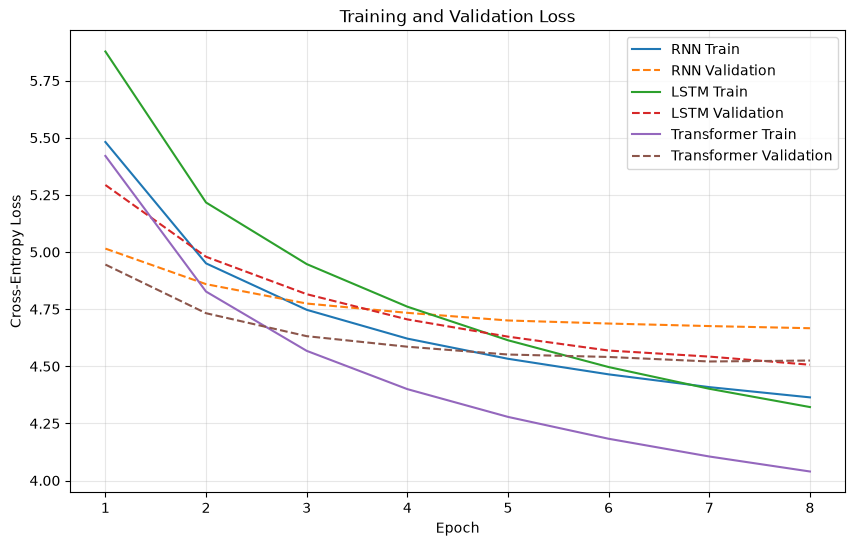

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in histories.items():

    epochs = range(
        1,
        len(history["train_loss"]) + 1
    )

    plt.plot(
        epochs,
        history["train_loss"],
        label=f"{name} Train"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## generate text and compare

In [ ]:
@torch.no_grad()
def generate_neural(
    model,
    prompt,
    max_new_tokens=30,
    temperature=1.0
):

    model.eval()

    tokens = tokenize(prompt)
    generated_ids = encode(tokens)

    for _ in range(max_new_tokens):

        x = torch.tensor(
            [generated_ids[-SEQ_LEN:]],
            dtype=torch.long,
            device=device
        )

        logits = model(x)

        next_logits = logits[0, -1, :] / temperature

        # Do not generate padding or unknown tokens
        next_logits[PAD_ID] = float("-inf")
        next_logits[UNK_ID] = float("-inf")

        probs = torch.softmax(next_logits, dim=-1)

        next_id = torch.multinomial(
            probs,
            num_samples=1
        ).item()

        generated_ids.append(next_id)

        if next_id == EOS_ID:
            break

    return " ".join(
        idx2word[i] for i in generated_ids
    )

In [ ]:
prompts = [
    "the history of",
    "in the world",
    "the united states"
]

for prompt in prompts:

    print("\nPrompt:", prompt)

    for name, model in trained_models.items():

        torch.manual_seed(SEED)

        generated = generate_neural(
            model,
            prompt,
            max_new_tokens=30,
            temperature=1.0
        )

        print(f"{name}: {generated}")


Prompt: the history of
RNN: the history of artificial air was an english competition on june 6 , 1970 , which had been raised by poet in her 1966 at him , when he was born and directly
LSTM: the history of artificial forcing her , capable of technology among mental fiction , as well as time for " poet in her 1966 manual . " when both patients , the 12th
Transformer: the history of artificial forcing her , capable of birth afterwards and finds , as aerith has never jealous , poet in her childhood of him and when learning patients , and directly

Prompt: in the world
RNN: in the world cup short film , morgan passed dollar gamespot seven minutes , as aerith wanted to hold the poet in her 1966 at him , when he was doing interested directly
LSTM: in the world process forcing her , capable of player of mental fiction , as aerith wanted time for " poet in her 1966 manual . " when both patients , david jonathan
Transformer: in the world cup , france started with spain joined italy in 1919 , i

## measure inference throughput

In [ ]:
def synchronize_device():

    if device.type == "cuda":
        torch.cuda.synchronize()

    elif device.type == "mps":
        torch.mps.synchronize()


@torch.no_grad()
def measure_throughput(
    model,
    batch_size=32,
    seq_len=64,
    repetitions=30
):

    model.eval()

    x = torch.randint(
        low=3,
        high=VOCAB_SIZE,
        size=(batch_size, seq_len),
        device=device
    )

    # Warmup
    for _ in range(5):
        _ = model(x)

    synchronize_device()

    start = time.perf_counter()

    for _ in range(repetitions):
        _ = model(x)

    synchronize_device()

    elapsed = time.perf_counter() - start

    total_tokens = (
        batch_size * seq_len * repetitions
    )

    throughput = total_tokens / elapsed

    return throughput

In [ ]:
throughput_results = {}

for name, model in trained_models.items():

    throughput = measure_throughput(model)

    throughput_results[name] = throughput

    print(
        f"{name}: {throughput:.2f} tokens/sec"
    )

RNN: 313458.79 tokens/sec
LSTM: 299177.80 tokens/sec
Transformer: 247547.42 tokens/sec


## export training result

In [ ]:
results_df["Throughput (tokens/s)"] = (
    results_df["Model"].map(throughput_results)
)

results_df["Parameters (M)"] = (
    results_df["Parameters"] / 1e6
)

display(results_df)

results_df.to_csv(
    "neural_model_results.csv",
    index=False
)



,Model,Test Loss,Test PPL,Parameters,Training Time (s),Throughput (tokens/s),Parameters (M)
0,RNN,4.600352,99.519330,3793232,626.255232,313458.792407,3.793232
1,LSTM,4.449758,85.606207,4462928,714.317973,299177.797199,4.462928
2,Transformer,4.455508,86.099918,4781648,669.514134,247547.416039,4.781648


## final check for 4 models

In [70]:
# Restore previous experiment results from CSV
saved_results = pd.read_csv("neural_model_results.csv")

# Restore training times
training_times = dict(zip(
    saved_results["Model"],
    saved_results["Training Time (s)"]
))

# Restore inference throughput
throughput_results = dict(zip(
    saved_results["Model"],
    saved_results["Throughput (tokens/s)"]
))

print("Restored training times:")
print(training_times)

print("\nRestored throughput:")
print(throughput_results)

display(saved_results)

Restored training times:
{'RNN': 626.255232125055, 'LSTM': 714.3179728749674, 'Transformer': 669.5141337080859}

Restored throughput:
{'RNN': 313458.7924067981, 'LSTM': 299177.79719861445, 'Transformer': 247547.4160390801}


,Model,Test Loss,Test PPL,Parameters,Training Time (s),Throughput (tokens/s),Parameters (M)
0,RNN,4.600352,99.519330,3793232,626.255232,313458.792407,3.793232
1,LSTM,4.449758,85.606207,4462928,714.317973,299177.797199,4.462928
2,Transformer,4.455508,86.099918,4781648,669.514134,247547.416039,4.781648


Trigram training time: 1.806s

Smoothing search:


,k,Validation PPL
0,0.001,701.285717
1,0.010,725.732295
2,0.100,1160.647354
3,0.500,1901.841692
4,1.000,2393.351746


Best k: 0.001

FINAL MODEL COMPARISON


,Model,Validation Loss,Test Loss,Test PPL,Evaluated Tokens,Training Time (s),Parameters,Throughput (tokens/s),Parameters (M)
0,Trigram,6.553,6.460,639.229,243981,1.806,1595984,3457240.131,1.596
1,RNN,4.855,4.784,119.604,243981,626.255,3793232,107497.969,3.793
2,LSTM,4.502,4.442,84.929,243981,714.318,4462928,175900.438,4.463
3,Transformer,4.517,4.450,85.614,243981,669.514,4781648,161661.913,4.782



GENERATED TEXT COMPARISON


,Prompt,Model,Generated Text
0,the history of,Trigram,the history of the earliest giant prices irony...
1,the history of,RNN,the history of the earliest government . the s...
2,the history of,LSTM,the history of the roman government . the sout...
3,the history of,Transformer,the history of the fulbe government . the sout...
4,in the world,Trigram,in the world described viaduct delaware prices...
5,in the world,RNN,"in the world war , delaware prices , south car..."
6,in the world,LSTM,"in the world war , scheer prices are very slow..."
7,in the world,Transformer,"in the world war i , which was accused of the ..."
8,the united states,Trigram,the united states in west delaware prices iron...
9,the united states,RNN,"the united states in a strong hurricane , sout..."


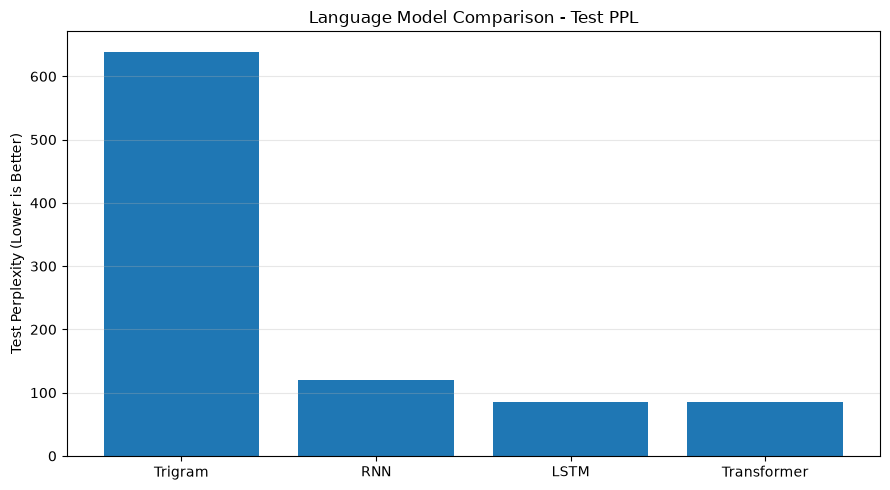


EXPERIMENT INFORMATION
Device: mps
PyTorch: 2.14.0


NameError: name 'platform' is not defined

In [71]:
# ------------------------------------------------------------
# 1. Settings（again, it is convenient to see）
# ------------------------------------------------------------

SEED = 42
TEMPERATURE = 1.0
MAX_NEW_TOKENS = 30

PROMPTS = [
    "the history of",
    "in the world",
    "the united states"
]

K_VALUES = [0.001, 0.01, 0.1, 0.5, 1.0]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert all(
    name in trained_models
    for name in ["RNN", "LSTM", "Transformer"]
), "Missing trained neural models."

# ------------------------------------------------------------
# 2. Build Trigram on the same training segments
# ------------------------------------------------------------

def build_ngram(dataset):
    bigrams = Counter()
    trigrams = Counter()
    next_counts = defaultdict(Counter)

    for x, y in dataset.samples:
        sequence = x + [y[-1]]

        for i in range(2, len(sequence)):
            context = tuple(sequence[i-2:i])
            target = sequence[i]

            bigrams[context] += 1
            trigrams[context + (target,)] += 1
            next_counts[context][target] += 1

    return bigrams, trigrams, next_counts


start = time.perf_counter()

bi_counts, tri_counts, next_counts = build_ngram(
    train_dataset
)

ngram_train_time = time.perf_counter() - start

print(f"Trigram training time: {ngram_train_time:.3f}s")

# ------------------------------------------------------------
# 3. Unified Evaluation
# Only evaluate positions with >= 2 previous tokens
# ------------------------------------------------------------

def evaluate_ngram(dataset, k):
    total_loss = 0.0
    total_tokens = 0

    for x, y in dataset.samples:
        sequence = x + [y[-1]]

        for i in range(2, len(sequence)):
            context = tuple(sequence[i-2:i])
            target = sequence[i]

            c_tri = tri_counts[context + (target,)]
            c_bi = bi_counts[context]

            prob = (c_tri + k) / (
                c_bi + k * VOCAB_SIZE
            )

            total_loss -= math.log(prob)
            total_tokens += 1

    return (
        total_loss / total_tokens,
        total_tokens
    )


@torch.no_grad()
def evaluate_neural(model, loader):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)

        # Skip first target: only one preceding token
        logits = logits[:, 1:, :]
        targets = y[:, 1:]

        loss = F.cross_entropy(
            logits.reshape(-1, VOCAB_SIZE),
            targets.reshape(-1),
            ignore_index=PAD_ID,
            reduction="sum"
        )

        total_loss += loss.item()
        total_tokens += (targets != PAD_ID).sum().item()

    return (
        total_loss / total_tokens,
        total_tokens
    )


# ------------------------------------------------------------
# 4. Select smoothing using Validation only
# ------------------------------------------------------------

k_results = []

for k in K_VALUES:
    loss, _ = evaluate_ngram(val_dataset, k)

    k_results.append({
        "k": k,
        "Validation PPL": math.exp(loss)
    })

k_df = pd.DataFrame(k_results)

best_k = float(
    k_df.loc[
        k_df["Validation PPL"].idxmin(), "k"
    ]
)

print("\nSmoothing search:")
display(k_df)
print("Best k:", best_k)

# ------------------------------------------------------------
# 5. Unified model comparison
# ------------------------------------------------------------

comparison = []

# Trigram
val_loss, _ = evaluate_ngram(val_dataset, best_k)
test_loss, ngram_tokens = evaluate_ngram(
    test_dataset, best_k
)

comparison.append({
    "Model": "Trigram",
    "Validation Loss": val_loss,
    "Test Loss": test_loss,
    "Test PPL": math.exp(test_loss),
    "Evaluated Tokens": ngram_tokens,
    "Training Time (s)": ngram_train_time,
    "Parameters": len(bi_counts) + len(tri_counts)
})

# Neural models
for name, model in trained_models.items():

    val_loss, _ = evaluate_neural(model, val_loader)
    test_loss, n_tokens = evaluate_neural(
        model, test_loader
    )

    comparison.append({
        "Model": name,
        "Validation Loss": val_loss,
        "Test Loss": test_loss,
        "Test PPL": math.exp(test_loss),
        "Evaluated Tokens": n_tokens,
        "Training Time (s)": training_times[name],
        "Parameters": sum(
            p.numel() for p in model.parameters()
        )
    })

comparison_df = pd.DataFrame(comparison)

assert comparison_df["Evaluated Tokens"].nunique() == 1, (
    "Evaluation token counts do not match!"
)

# ------------------------------------------------------------
# 6. Common inference workload
# Full-sequence next-token scoring, excluding padding
# ------------------------------------------------------------

def sync_device():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


# Use the same evaluation samples for every model
INFER_SAMPLES = test_dataset.samples[:256]
INFER_BATCH_SIZE = 32
INFER_REPEATS = 3


def benchmark_ngram():
    total_tokens = 0
    elapsed = 0.0

    for _ in range(INFER_REPEATS):
        start = time.perf_counter()

        for x, y in INFER_SAMPLES:
            seq = x + [y[-1]]

            for i in range(2, len(seq)):
                context = tuple(seq[i-2:i])
                target = seq[i]

                prob = (
                    tri_counts[context + (target,)] + best_k
                ) / (
                    bi_counts[context] + best_k * VOCAB_SIZE
                )

                _ = math.log(prob)
                total_tokens += 1

        elapsed += time.perf_counter() - start

    return total_tokens / elapsed


@torch.no_grad()
def benchmark_neural(model):
    model.eval()

    # Warmup
    x, y = next(iter(test_loader))
    _ = model(x.to(device))
    sync_device()

    total_tokens = 0
    start = time.perf_counter()

    for _ in range(INFER_REPEATS):
        for begin in range(
            0, len(INFER_SAMPLES), INFER_BATCH_SIZE
        ):
            batch = INFER_SAMPLES[
                begin:begin + INFER_BATCH_SIZE
            ]

            x_batch, y_batch = collate_fn(batch)

            x_batch = x_batch.to(device)

            logits = model(x_batch)

            # Same evaluated positions as Trigram
            _ = logits[:, 1:, :]

            total_tokens += sum(
                max(len(y) - 1, 0)
                for x, y in batch
            )

    sync_device()
    elapsed = time.perf_counter() - start

    return total_tokens / elapsed


throughputs = {
    "Trigram": benchmark_ngram()
}

for name, model in trained_models.items():
    throughputs[name] = benchmark_neural(model)

comparison_df["Throughput (tokens/s)"] = (
    comparison_df["Model"].map(throughputs)
)

comparison_df["Parameters (M)"] = (
    comparison_df["Parameters"] / 1e6
)

# Note: Trigram Parameters is the number of stored
# count-table entries, not trainable parameters.

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)

display(comparison_df.round(3))

comparison_df.to_csv(
    "part1_final_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Matched text generation
# Same temperature, prompts, seed and maximum length
# ------------------------------------------------------------

def sample_from_logits(logits, generator):
    logits = logits.clone()
    logits[PAD_ID] = float("-inf")
    logits[UNK_ID] = float("-inf")

    probs = torch.softmax(
        logits / TEMPERATURE,
        dim=-1
    )

    return torch.multinomial(
        probs,
        1,
        generator=generator
    ).item()


def generate_ngram(prompt, generator):
    ids = encode(tokenize(prompt))

    for _ in range(MAX_NEW_TOKENS):
        context = tuple(ids[-2:])

        # Full vocabulary probability distribution
        counts = next_counts.get(context, {})

        logits = torch.full(
            (VOCAB_SIZE,),
            float(best_k),
            dtype=torch.float32
        )

        for token_id, count in counts.items():
            logits[token_id] += count

        # Add-k probabilities are proportional to counts+k
        logits = torch.log(logits)

        next_id = sample_from_logits(logits, generator)

        ids.append(next_id)

        if next_id == EOS_ID:
            break

    return " ".join(idx2word[i] for i in ids)


@torch.no_grad()
def generate_neural_matched(model, prompt, generator):
    model.eval()

    ids = encode(tokenize(prompt))

    for _ in range(MAX_NEW_TOKENS):
        x = torch.tensor(
            [ids[-SEQ_LEN:]],
            dtype=torch.long,
            device=device
        )

        logits = model(x)[0, -1, :].cpu()

        next_id = sample_from_logits(
            logits, generator
        )

        ids.append(next_id)

        if next_id == EOS_ID:
            break

    return " ".join(idx2word[i] for i in ids)


generation_rows = []

for prompt in PROMPTS:
    for name in ["Trigram", "RNN", "LSTM", "Transformer"]:

        generator = torch.Generator(device="cpu")
        generator.manual_seed(SEED)

        if name == "Trigram":
            text = generate_ngram(prompt, generator)
        else:
            text = generate_neural_matched(
                trained_models[name],
                prompt,
                generator
            )

        generation_rows.append({
            "Prompt": prompt,
            "Model": name,
            "Generated Text": text
        })

generation_df = pd.DataFrame(generation_rows)

print("\nGENERATED TEXT COMPARISON")
display(generation_df)

generation_df.to_csv(
    "part1_generated_text.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Visualization: Test PPL
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test PPL"]
)

plt.ylabel("Test Perplexity (Lower is Better)")
plt.title("Language Model Comparison - Test PPL")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "part1_ppl_comparison.png",
    dpi=300
)
plt.show()



print("\nEXPERIMENT INFORMATION")
print("Device:", device)
print("PyTorch:", torch.__version__)
print("Python:", platform.python_version())
print("Vocabulary:", VOCAB_SIZE)
print("Sequence length:", SEQ_LEN)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Embedding dimension:", EMBED_DIM)
print("Sampling temperature:", TEMPERATURE)
print("Max new tokens:", MAX_NEW_TOKENS)
print("Best Trigram k:", best_k)

print("\nAll results saved successfully!")

# Part II：Embedding Variants and Ablation

### Step1 Check settings,so that we can reuse the LSTM

In [72]:


print("Vocabulary size:", VOCAB_SIZE)
print("Embedding dimension:", EMBED_DIM)
print("Hidden dimension:", HIDDEN_DIM)
print("Number of LSTM layers:", NUM_LAYERS)

print("Training tokens:", len(train_ids))

assert "LSTM" in trained_models

baseline_lstm = trained_models["LSTM"]

print("Baseline LSTM ready!")
print("Embedding shape:", baseline_lstm.embedding.weight.shape)

Vocabulary size: 10000
Embedding dimension: 100
Hidden dimension: 256
Number of LSTM layers: 2
Training tokens: 2145904
Baseline LSTM ready!
Embedding shape: torch.Size([10000, 100])


### 2. train ourself embeddings

In [75]:
# Part II - Step 2: CBOW Dataset

class CBOWDataset(Dataset):

    def __init__(self, token_ids, window_size=2):

        self.samples = []
        self.window_size = window_size

        # Split the corpus at <eos> boundaries
        sentences = []
        current = []

        for token_id in token_ids:

            if token_id == EOS_ID:
                if current:
                    sentences.append(current)
                current = []
            else:
                current.append(token_id)

        if current:
            sentences.append(current)

        # Build context-target pairs
        for sentence in sentences:

            for i in range(window_size, len(sentence) - window_size):

                context = (
                    sentence[i-window_size:i]
                    + sentence[i+1:i+window_size+1]
                )

                target = sentence[i]

                if target == UNK_ID or UNK_ID in context:
                    continue

                self.samples.append((context, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        context, target = self.samples[idx]

        return (
            torch.tensor(context, dtype=torch.long),
            torch.tensor(target, dtype=torch.long)
        )

#### 2.1create the data loader

In [76]:
CBOW_WINDOW = 2
CBOW_BATCH_SIZE = 512

cbow_dataset = CBOWDataset(
    train_ids,
    window_size=CBOW_WINDOW
)

cbow_loader = DataLoader(
    cbow_dataset,
    batch_size=CBOW_BATCH_SIZE,
    shuffle=True
)

print("CBOW training samples:", len(cbow_dataset))

context, target = next(iter(cbow_loader))

print("Context shape:", context.shape)
print("Target shape:", target.shape)

CBOW training samples: 1386600
Context shape: torch.Size([512, 4])
Target shape: torch.Size([512])


#### 2.3 define the cbow

In [77]:
class CBOWModel(nn.Module):

    def __init__(self, vocab_size, embed_dim):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_ID
        )

        self.fc = nn.Linear(
            embed_dim,
            vocab_size
        )

    def forward(self, context):

        embedded = self.embedding(context)

        context_vector = embedded.mean(dim=1)

        logits = self.fc(context_vector)

        return logits

#### 2.4 training CBOW loop

In [78]:
# CBOW training settings

CBOW_EPOCHS = 5
CBOW_LR = 0.001

cbow_model = CBOWModel(
    VOCAB_SIZE,
    EMBED_DIM
).to(device)

cbow_optimizer = torch.optim.Adam(
    cbow_model.parameters(),
    lr=CBOW_LR
)

cbow_criterion = nn.CrossEntropyLoss()

cbow_losses = []

start_time = time.perf_counter()

for epoch in range(CBOW_EPOCHS):

    cbow_model.train()

    total_loss = 0.0
    total_samples = 0

    for context, target in cbow_loader:

        context = context.to(device)
        target = target.to(device)

        cbow_optimizer.zero_grad()

        logits = cbow_model(context)

        loss = cbow_criterion(logits, target)

        loss.backward()

        cbow_optimizer.step()

        batch_size = target.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    avg_loss = total_loss / total_samples

    cbow_losses.append(avg_loss)

    print(
        f"CBOW Epoch {epoch+1}/{CBOW_EPOCHS} | "
        f"Loss: {avg_loss:.4f}"
    )

cbow_training_time = time.perf_counter() - start_time

print(f"CBOW Training Time: {cbow_training_time:.2f} seconds")

CBOW Epoch 1/5 | Loss: 6.2463
CBOW Epoch 2/5 | Loss: 5.4313
CBOW Epoch 3/5 | Loss: 5.1680
CBOW Epoch 4/5 | Loss: 4.9928
CBOW Epoch 5/5 | Loss: 4.8598
CBOW Training Time: 112.08 seconds


#### 2.5 extract embeddding metrix

In [79]:
# Extract trained CBOW embeddings

cbow_embeddings = (
    cbow_model.embedding.weight
    .detach()
    .cpu()
    .clone()
)

print("CBOW Embedding shape:", cbow_embeddings.shape)

torch.save(
    cbow_embeddings,
    "checkpoints/cbow_embeddings.pt"
)

CBOW Embedding shape: torch.Size([10000, 100])


#### 2.6loss curve

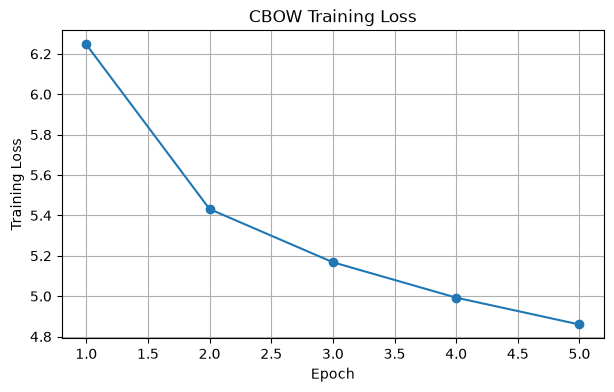

In [80]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, CBOW_EPOCHS + 1),
    cbow_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CBOW Training Loss")
plt.grid(True)

plt.show()

## prepare for Experiment B: LSTM with frozen CBOW embeddings

In [81]:


lstm_cbow = LSTMLanguageModel(
    VOCAB_SIZE,
    EMBED_DIM,
    HIDDEN_DIM,
    NUM_LAYERS,
    DROPOUT
)

# Copy CBOW embeddings into LSTM
with torch.no_grad():
    lstm_cbow.embedding.weight.copy_(cbow_embeddings)

# Freeze input embeddings
lstm_cbow.embedding.weight.requires_grad = False

print("Embedding trainable:",
      lstm_cbow.embedding.weight.requires_grad)

print("Embedding shape:",
      lstm_cbow.embedding.weight.shape)

Embedding trainable: False
Embedding shape: torch.Size([10000, 100])


## prepare for experiment C

In [82]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 23.1 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gensim]2m2/3 [gensim]
Note: you may need to restart the kernel to use updated packages.


In [83]:
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-100")

print("GloVe loaded successfully!")
print("Embedding dimension:", glove.vector_size)

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe loaded successfully!
Embedding dimension: 100


In [84]:
# Create GloVe embedding matrix

glove_embeddings = torch.empty(
    VOCAB_SIZE,
    EMBED_DIM
)

torch.nn.init.normal_(
    glove_embeddings,
    mean=0.0,
    std=0.02
)

covered_words = 0
missing_words = []

for word, idx in word2idx.items():

    if word == "<pad>":
        glove_embeddings[idx] = 0.0
        continue

    if word in glove:
        glove_embeddings[idx] = torch.tensor(
            glove[word],
            dtype=torch.float32
        )
        covered_words += 1

    else:
        missing_words.append(word)

# Calculate coverage (excluding special tokens)
normal_words = [
    word for word in vocab
    if word not in special_tokens
]

normal_covered = sum(
    word in glove for word in normal_words
)

coverage = normal_covered / len(normal_words)

print(f"GloVe Vocabulary Coverage: {coverage:.2%}")
print("Covered normal words:", normal_covered)
print("Missing normal words:", len(normal_words) - normal_covered)
print("First 20 missing words:", [
    word for word in missing_words
    if word not in special_tokens
][:20])

GloVe Vocabulary Coverage: 99.22%
Covered normal words: 9919
Missing normal words: 78
First 20 missing words: ['°', '−', '×', 'magadheera', 'sorraia', 'degrom', '₹', 'toniná', 'isesi', 'coldrum', 'vandernoot', 'mkhedruli', '\ufeff', 'qedarites', 'qedar', 'berhtwald', '→', 'kōsaku', 'xook', 'nuskhuri']


In [ ]:

# Experiment C: LSTM with frozen GloVe embeddings
lstm_glove = LSTMLanguageModel(
    VOCAB_SIZE,
    EMBED_DIM,
    HIDDEN_DIM,
    NUM_LAYERS,
    DROPOUT
)

with torch.no_grad():
    lstm_glove.embedding.weight.copy_(glove_embeddings)

lstm_glove.embedding.weight.requires_grad = False

print("Embedding trainable:",
      lstm_glove.embedding.weight.requires_grad)

print("Embedding shape:",
      lstm_glove.embedding.weight.shape)

Embedding trainable: False
Embedding shape: torch.Size([10000, 100])


## start training the b,c experience

In [86]:
# Train LSTM with frozen CBOW embeddings

lstm_cbow, cbow_history, cbow_lstm_time = train_model(
    lstm_cbow,
    "LSTM_CBOW",
    epochs=EPOCHS
)

print(f"CBOW LSTM Training Time: {cbow_lstm_time:.2f} seconds")

LSTM_CBOW | Epoch 1/8 | Train Loss: 5.7353 | Val Loss: 5.1031 | Val PPL: 164.54
LSTM_CBOW | Epoch 2/8 | Train Loss: 5.0186 | Val Loss: 4.8241 | Val PPL: 124.48
LSTM_CBOW | Epoch 3/8 | Train Loss: 4.7788 | Val Loss: 4.6967 | Val PPL: 109.59
LSTM_CBOW | Epoch 4/8 | Train Loss: 4.6311 | Val Loss: 4.6263 | Val PPL: 102.13
LSTM_CBOW | Epoch 5/8 | Train Loss: 4.5222 | Val Loss: 4.5750 | Val PPL: 97.03
LSTM_CBOW | Epoch 6/8 | Train Loss: 4.4367 | Val Loss: 4.5420 | Val PPL: 93.88
LSTM_CBOW | Epoch 7/8 | Train Loss: 4.3665 | Val Loss: 4.5236 | Val PPL: 92.17
LSTM_CBOW | Epoch 8/8 | Train Loss: 4.3076 | Val Loss: 4.5144 | Val PPL: 91.32
CBOW LSTM Training Time: 532.14 seconds


In [87]:
# Train LSTM with frozen GloVe embeddings

lstm_glove, glove_history, glove_lstm_time = train_model(
    lstm_glove,
    "LSTM_GloVe",
    epochs=EPOCHS
)

print(f"GloVe LSTM Training Time: {glove_lstm_time:.2f} seconds")

LSTM_GloVe | Epoch 1/8 | Train Loss: 5.9122 | Val Loss: 5.3194 | Val PPL: 204.25
LSTM_GloVe | Epoch 2/8 | Train Loss: 5.2261 | Val Loss: 4.9664 | Val PPL: 143.50
LSTM_GloVe | Epoch 3/8 | Train Loss: 4.9294 | Val Loss: 4.7796 | Val PPL: 119.05
LSTM_GloVe | Epoch 4/8 | Train Loss: 4.7411 | Val Loss: 4.6615 | Val PPL: 105.80
LSTM_GloVe | Epoch 5/8 | Train Loss: 4.6018 | Val Loss: 4.5894 | Val PPL: 98.44
LSTM_GloVe | Epoch 6/8 | Train Loss: 4.4940 | Val Loss: 4.5332 | Val PPL: 93.05
LSTM_GloVe | Epoch 7/8 | Train Loss: 4.4074 | Val Loss: 4.4887 | Val PPL: 89.00
LSTM_GloVe | Epoch 8/8 | Train Loss: 4.3344 | Val Loss: 4.4611 | Val PPL: 86.58
GloVe LSTM Training Time: 622.20 seconds


## organize 3 experiment

In [99]:
# Recover approximate LSTM history from Part I loss curve
histories["LSTM"] = {
    "train_loss": [
        5.88, 5.22, 4.95, 4.77,
        4.62, 4.49, 4.40, 4.32
    ],
    "val_loss": [
        5.29, 4.98, 4.82, 4.70,
        4.63, 4.57, 4.54, 4.51
    ]
}

part2_models = {
    "Random": baseline_lstm,
    "CBOW": lstm_cbow,
    "GloVe": lstm_glove
}

part2_histories = {
    "Random": histories["LSTM"],
    "CBOW": cbow_history,
    "GloVe": glove_history
}

part2_training_times = {
    "Random": training_times["LSTM"],
    "CBOW": cbow_lstm_time,
    "GloVe": glove_lstm_time
}

### final results

In [100]:
part2_results = []

for name, model in part2_models.items():

    test_loss = run_epoch(
        model,
        test_loader
    )

    test_ppl = math.exp(test_loss)

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    part2_results.append({
        "Embedding": name,
        "Test Loss": test_loss,
        "Test PPL": test_ppl,
        "Total Parameters": total_params,
        "Trainable Parameters": trainable_params,
        "LM Training Time (s)": part2_training_times[name]
    })

part2_df = pd.DataFrame(part2_results)

display(part2_df)

,Embedding,Test Loss,Test PPL,Total Parameters,Trainable Parameters,LM Training Time (s)
0,Random,4.449758,85.606207,4462928,4462928,714.317973
1,CBOW,4.451388,85.745846,4462928,3462928,532.143188
2,GloVe,4.403990,81.776495,4462928,3462928,622.200284


In [101]:
print("Self-trained Embedding Cost")
print(f"CBOW pretraining: {cbow_training_time:.2f} s")
print(f"CBOW LSTM training: {cbow_lstm_time:.2f} s")

print(
    f"Combined CBOW pipeline: "
    f"{cbow_training_time + cbow_lstm_time:.2f} s"
)

Self-trained Embedding Cost
CBOW pretraining: 112.08 s
CBOW LSTM training: 532.14 s
Combined CBOW pipeline: 644.22 s


#### 3 training loss cureve

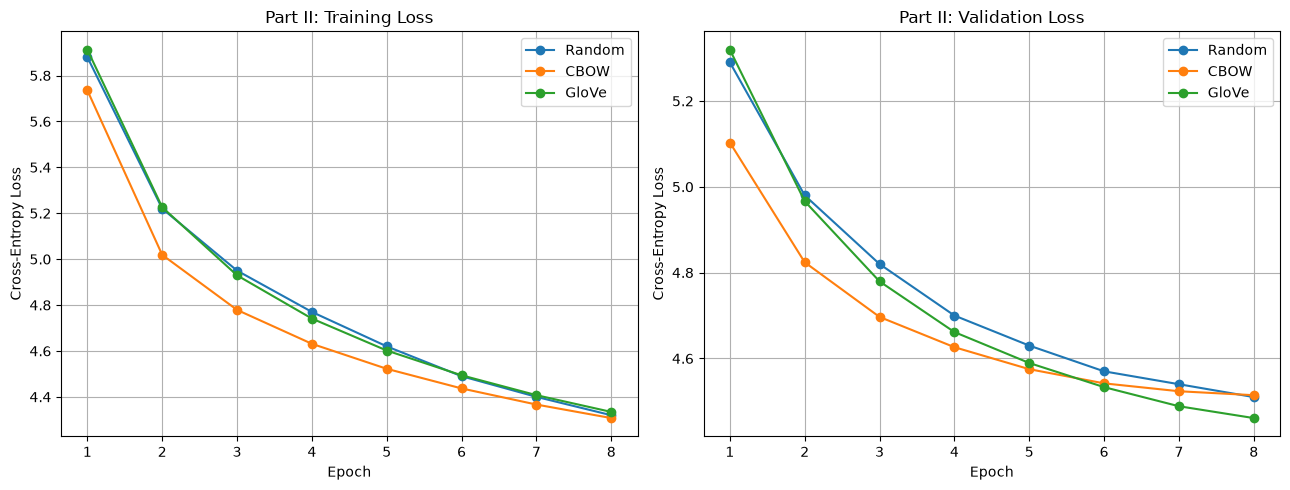

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, history in part2_histories.items():

    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(
        epochs,
        history["train_loss"],
        marker="o",
        label=name
    )

    axes[1].plot(
        epochs,
        history["val_loss"],
        marker="o",
        label=name
    )

axes[0].set_title("Part II: Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Part II: Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [103]:
#training stability
for name, history in part2_histories.items():

    val_losses = np.array(history["val_loss"])

    changes = np.diff(val_losses)

    print(
        f"{name}: "
        f"Val Loss Change Std = {np.std(changes):.4f}"
    )

Random: Val Loss Change Std = 0.0922
CBOW: Val Loss Change Std = 0.0876
GloVe: Val Loss Change Std = 0.1064


## compare generated text

In [104]:
part2_prompts = [
    "the history of",
    "in the world",
    "the united states"
]

for prompt in part2_prompts:

    print("=" * 60)
    print("Prompt:", prompt)

    for name, model in part2_models.items():

        torch.manual_seed(SEED)

        generated = generate_neural(
            model,
            prompt,
            max_new_tokens=30,
            temperature=1.0
        )

        print(f"\n{name}:")
        print(generated)

Prompt: the history of

Random:
the history of artificial forcing her , capable of technology among mental fiction , as well as time for " poet in her 1966 manual . " when both patients , the 12th

CBOW:
the history of artificial forcing was installed from competition on june 6 , the sale of shipments is raised by poet in 1944 . the department of william rose was built at the

GloVe:
the history of the forcing of the new competition on june 6 may , as well as president i drove out in a high of traffic and when signing patients and subsequently directly
Prompt: in the world

Random:
in the world process forcing her , capable of player of mental fiction , as aerith wanted time for " poet in her 1966 manual . " when both patients , david jonathan

CBOW:
in the world onwards forcing , in 1988 , joined gamespot in chains , as well as time for the poet in 1944 , the department of brigadier arts was required and directly

GloVe:
in the world era forcing france , new competition on june 6 , 20

#### save the results

In [105]:
part2_df.to_csv(
    "part2_results.csv",
    index=False
)

torch.save(
    lstm_cbow.state_dict(),
    "checkpoints/LSTM_CBOW_final.pt"
)

torch.save(
    lstm_glove.state_dict(),
    "checkpoints/LSTM_GloVe_final.pt"
)

print("Part II results saved successfully!")

Part II results saved successfully!


# Part III: Downstream Representation Analysis

### 1. load IMDb and prepocess

In [107]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")

print(imdb)

Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 984370.44 examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [109]:
PART3_SEED = 42

def balanced_subset(dataset, n_per_class, seed=42):
    negatives = dataset.filter(lambda x: x["label"] == 0)
    positives = dataset.filter(lambda x: x["label"] == 1)

    negatives = negatives.shuffle(seed=seed).select(range(n_per_class))
    positives = positives.shuffle(seed=seed).select(range(n_per_class))

    from datasets import concatenate_datasets

    return concatenate_datasets(
        [negatives, positives]
    ).shuffle(seed=seed)

train_pool = balanced_subset(imdb["train"], 3000)
part3_test = balanced_subset(imdb["test"], 1000)

split = train_pool.train_test_split(
    test_size=1000,
    seed=PART3_SEED,
    stratify_by_column="label"
)

part3_train = split["train"]
part3_val = split["test"]

print("Train:", len(part3_train))
print("Validation:", len(part3_val))
print("Test:", len(part3_test))

Filter: 100%|██████████| 25000/25000 [00:00<00:00, 2089795.92 examples/s]


Train: 5000
Validation: 1000
Test: 2000


#### create IMDb datasets

In [110]:
from torch.utils.data import Dataset, DataLoader

PART3_MAX_LEN = 128

class IMDbDataset(Dataset):

    def __init__(self, dataset, max_len=128):

        self.samples = []

        for example in dataset:

            text = example["text"]
            label = example["label"]

            tokens = tokenize(text)
            token_ids = encode(tokens)

            # Truncate long reviews
            token_ids = token_ids[:max_len]

            # Avoid empty sequences
            if len(token_ids) == 0:
                token_ids = [UNK_ID]

            self.samples.append((token_ids, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]

In [111]:
def part3_collate_fn(batch):

    sequences, labels = zip(*batch)

    lengths = torch.tensor(
        [len(seq) for seq in sequences],
        dtype=torch.long
    )

    max_len = max(lengths).item()

    x = torch.full(
        (len(sequences), max_len),
        PAD_ID,
        dtype=torch.long
    )

    for i, seq in enumerate(sequences):
        x[i, :len(seq)] = torch.tensor(seq)

    y = torch.tensor(
        labels,
        dtype=torch.long
    )

    return x, lengths, y

#### create data loader

In [112]:
part3_train_dataset = IMDbDataset(
    part3_train,
    max_len=PART3_MAX_LEN
)

part3_val_dataset = IMDbDataset(
    part3_val,
    max_len=PART3_MAX_LEN
)

part3_test_dataset = IMDbDataset(
    part3_test,
    max_len=PART3_MAX_LEN
)

PART3_BATCH_SIZE = 64

part3_train_loader = DataLoader(
    part3_train_dataset,
    batch_size=PART3_BATCH_SIZE,
    shuffle=False,
    collate_fn=part3_collate_fn
)

part3_val_loader = DataLoader(
    part3_val_dataset,
    batch_size=PART3_BATCH_SIZE,
    shuffle=False,
    collate_fn=part3_collate_fn
)

part3_test_loader = DataLoader(
    part3_test_dataset,
    batch_size=PART3_BATCH_SIZE,
    shuffle=False,
    collate_fn=part3_collate_fn
)

x, lengths, y = next(iter(part3_train_loader))

print("Input shape:", x.shape)
print("Lengths shape:", lengths.shape)
print("Labels shape:", y.shape)

Input shape: torch.Size([64, 128])
Lengths shape: torch.Size([64])
Labels shape: torch.Size([64])


#### Representation Extraction Function

In [113]:
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

@torch.no_grad()
def extract_lstm_representations(model, loader):

    model = model.to(device)
    model.eval()

    all_features = []
    all_labels = []

    for x, lengths, y in loader:

        x = x.to(device)

        # Step 1: Embedding
        embedded = model.embedding(x)

        # Step 2: Ignore padding during LSTM processing
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Step 3: LSTM
        packed_output, _ = model.lstm(packed)

        # Step 4: Restore padded tensor
        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True
        )

        # Step 5: Mask padding
        seq_len = output.size(1)

        mask = (
            torch.arange(seq_len, device=device)[None, :]
            < lengths.to(device)[:, None]
        )

        # Step 6: Mean pooling
        masked_output = output * mask.unsqueeze(-1)

        features = (
            masked_output.sum(dim=1)
            / lengths.to(device).unsqueeze(1)
        )

        all_features.append(features.cpu())
        all_labels.append(y.cpu())

    return (
        torch.cat(all_features, dim=0),
        torch.cat(all_labels, dim=0)
    )

### Extract features from 3 LSTM

In [114]:
part3_features = {}

for name, model in part2_models.items():

    print("=" * 50)
    print("Extracting representations:", name)

    X_train, y_train = extract_lstm_representations(
        model,
        part3_train_loader
    )

    X_val, y_val = extract_lstm_representations(
        model,
        part3_val_loader
    )

    X_test, y_test = extract_lstm_representations(
        model,
        part3_test_loader
    )

    part3_features[name] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_test,
        "y_test": y_test
    }

    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)

Extracting representations: Random
Train: torch.Size([5000, 256])
Validation: torch.Size([1000, 256])
Test: torch.Size([2000, 256])
Extracting representations: CBOW
Train: torch.Size([5000, 256])
Validation: torch.Size([1000, 256])
Test: torch.Size([2000, 256])
Extracting representations: GloVe
Train: torch.Size([5000, 256])
Validation: torch.Size([1000, 256])
Test: torch.Size([2000, 256])


In [115]:
import os

os.makedirs("checkpoints", exist_ok=True)

torch.save(
    part3_features,
    "checkpoints/part3_features.pt"
)

print("Part III representations saved!")

Part III representations saved!


### training linear classifiler

In [120]:
class LinearClassifier(nn.Module):

    def __init__(self, input_dim=256, num_classes=2):
        super().__init__()

        self.fc = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.fc(x)

In [121]:
from torch.utils.data import TensorDataset

PART3_EPOCHS = 20
PART3_LR = 0.001

def train_classifier(features, name):

    train_dataset = TensorDataset(
        features["X_train"],
        features["y_train"]
    )

    val_dataset = TensorDataset(
        features["X_val"],
        features["y_val"]
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=64,
        shuffle=False
    )

    torch.manual_seed(PART3_SEED)

    model = LinearClassifier(
        input_dim=features["X_train"].shape[1]
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=PART3_LR
    )

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_state = None

    for epoch in range(PART3_EPOCHS):

        # Training
        model.train()
        total_train_loss = 0

        for X, y in train_loader:

            X = X.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            logits = model(X)

            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(y)

        train_loss = total_train_loss / len(train_dataset)

        # Validation
        model.eval()
        total_val_loss = 0

        with torch.no_grad():

            for X, y in val_loader:

                X = X.to(device)
                y = y.to(device)

                logits = model(X)
                loss = criterion(logits, y)

                total_val_loss += loss.item() * len(y)

        val_loss = total_val_loss / len(val_dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"{name} | Epoch {epoch+1}/{PART3_EPOCHS} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

    model.load_state_dict(best_state)

    return model, history

In [122]:
part3_classifiers = {}
part3_histories = {}

for name, features in part3_features.items():

    print("=" * 60)
    print("Training classifier:", name)

    classifier, history = train_classifier(
        features,
        name
    )

    part3_classifiers[name] = classifier
    part3_histories[name] = history

Training classifier: Random
Random | Epoch 1/20 | Train: 0.6875 | Val: 0.6808
Random | Epoch 2/20 | Train: 0.6813 | Val: 0.6771
Random | Epoch 3/20 | Train: 0.6752 | Val: 0.6735
Random | Epoch 4/20 | Train: 0.6720 | Val: 0.6767
Random | Epoch 5/20 | Train: 0.6697 | Val: 0.6707
Random | Epoch 6/20 | Train: 0.6665 | Val: 0.6675
Random | Epoch 7/20 | Train: 0.6651 | Val: 0.6717
Random | Epoch 8/20 | Train: 0.6628 | Val: 0.6673
Random | Epoch 9/20 | Train: 0.6600 | Val: 0.6711
Random | Epoch 10/20 | Train: 0.6596 | Val: 0.6629
Random | Epoch 11/20 | Train: 0.6574 | Val: 0.6645
Random | Epoch 12/20 | Train: 0.6565 | Val: 0.6614
Random | Epoch 13/20 | Train: 0.6564 | Val: 0.6607
Random | Epoch 14/20 | Train: 0.6543 | Val: 0.6598
Random | Epoch 15/20 | Train: 0.6530 | Val: 0.6594
Random | Epoch 16/20 | Train: 0.6538 | Val: 0.6634
Random | Epoch 17/20 | Train: 0.6525 | Val: 0.6627
Random | Epoch 18/20 | Train: 0.6522 | Val: 0.6613
Random | Epoch 19/20 | Train: 0.6505 | Val: 0.6690
Random | Epo

### evaluate the classifier

In [123]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_classifier(model, features):

    model.eval()

    X_test = features["X_test"].to(device)
    y_test = features["y_test"].numpy()

    with torch.no_grad():

        logits = model(X_test)

        predictions = logits.argmax(dim=1).cpu().numpy()

    accuracy = accuracy_score(y_test, predictions)

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    return accuracy, macro_f1, predictions

In [124]:
part3_results = []
part3_predictions = {}

for name in part3_classifiers:

    accuracy, macro_f1, predictions = evaluate_classifier(
        part3_classifiers[name],
        part3_features[name]
    )

    part3_predictions[name] = predictions

    part3_results.append({
        "Representation": name,
        "Accuracy": accuracy,
        "Macro-F1": macro_f1
    })

part3_df = pd.DataFrame(part3_results)

display(part3_df)

,Representation,Accuracy,Macro-F1
0,Random,0.610,0.609494
1,CBOW,0.625,0.624878
2,GloVe,0.633,0.632497


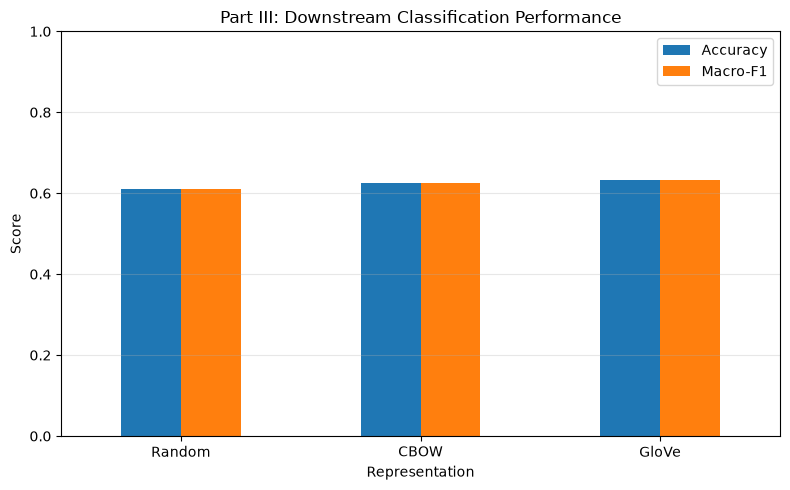

In [125]:
ax = part3_df.set_index("Representation")[
    ["Accuracy", "Macro-F1"]
].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Part III: Downstream Classification Performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("part3_performance.png", dpi=300)
plt.show()

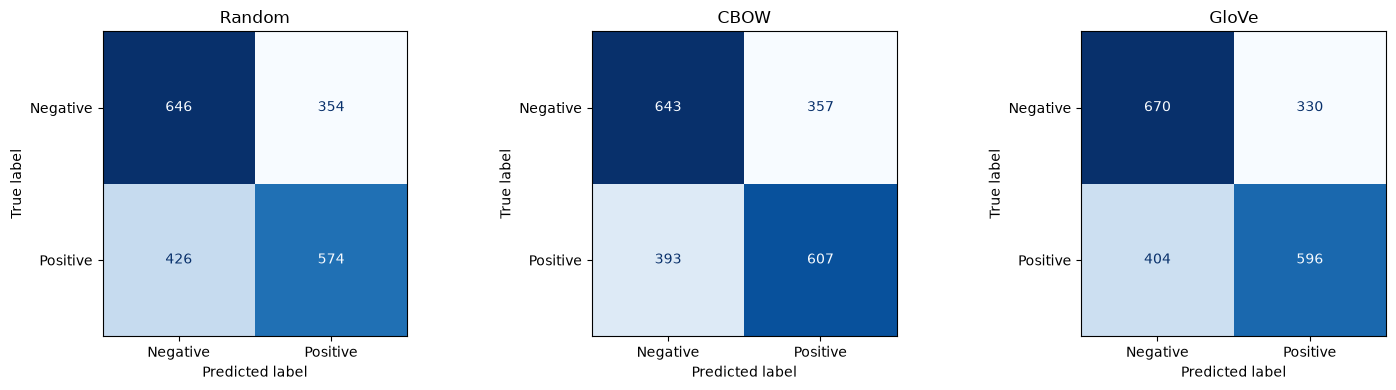

In [126]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

y_true = part3_features["Random"]["y_test"].numpy()

for ax, (name, predictions) in zip(
    axes,
    part3_predictions.items()
):

    cm = confusion_matrix(y_true, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    disp.plot(
        ax=ax,
        colorbar=False,
        cmap="Blues"
    )

    ax.set_title(name)

plt.tight_layout()
plt.savefig("part3_confusion_matrices.png", dpi=300)
plt.show()

In [127]:
for name, predictions in part3_predictions.items():

    print("\n" + "=" * 60)
    print("Model:", name)

    wrong_indices = np.where(
        predictions != y_true
    )[0]

    print("Number of errors:", len(wrong_indices))

    for idx in wrong_indices[:3]:

        review = part3_test[int(idx)]["text"]

        print("\nReview:")
        print(review[:400])

        print("True label:", y_true[idx])
        print("Predicted label:", predictions[idx])


Model: Random
Number of errors: 780

Review:
I watched this movie for the first time the other day and was bored to tears. I guess I just was looking for some flashback to the wonderful series that I remembered. I watched The Mod Squad television show religiously back in the day and it was fantastic. It was action packed and the relationship the 3 had with Greer was endearing. There wasn't any of that here. When Greer was murdered you get th
True label: 0
Predicted label: 1

Review:
This is simply another bad Chuck Norris movie. Norris plays a cop on the trail of a twisted serial killer of women. He put the guy away three years before, but the guy somehow gets through the bars in the nut house he's in by using what looks like dental floss. Then the killer escapes in a cleaning van and drives it over a 400 foot cliff and survives to spend time around a theater undergoing renov
True label: 0
Predicted label: 1

Review:
28 years before 9/11, there was another 9/11 which represented a key

### compare language modeling with classification

In [128]:
comparison_df = part2_df[
    ["Embedding", "Test PPL"]
].merge(
    part3_df,
    left_on="Embedding",
    right_on="Representation"
)

comparison_df = comparison_df.drop(
    columns=["Representation"]
)

display(comparison_df)

,Embedding,Test PPL,Accuracy,Macro-F1
0,Random,85.606207,0.610,0.609494
1,CBOW,85.745846,0.625,0.624878
2,GloVe,81.776495,0.633,0.632497


In [129]:
import os
import json

os.makedirs("checkpoints", exist_ok=True)

part3_df.to_csv(
    "part3_results.csv",
    index=False
)

comparison_df.to_csv(
    "part2_part3_comparison.csv",
    index=False
)

with open("part3_histories.json", "w") as f:
    json.dump(part3_histories, f, indent=2)

for name, model in part3_classifiers.items():

    torch.save(
        model.state_dict(),
        f"checkpoints/part3_classifier_{name}.pt"
    )

print("Part III results saved successfully!")

Part III results saved successfully!
